In [1]:
# Python = programming language
# SQL    = database query language

# pandas = Python tool for working with tables
# DuckDB = database engine that executes SQL

import pandas as pd
import duckdb

In [2]:
con = duckdb.connect("../natural_gas.db") # duckdb.connect() connects Python to a DuckDB database, and we're calling it "con" (short for connection)

In [3]:
con.sql("""
    SELECT *
    FROM read_csv_auto('../data/processed/henry_hub_monthly.csv')
    LIMIT 5
""")

# SELECT *       → select all columns
# FROM ...       → from this data source
# LIMIT 5        → but only return 5 rows

┌────────────┬────────────────────┐
│    Date    │       price        │
│    date    │       double       │
├────────────┼────────────────────┤
│ 1997-01-31 │           3.555625 │
│ 1997-02-28 │ 2.1993333333333336 │
│ 1997-03-31 │ 1.8970588235294117 │
│ 1997-04-30 │ 2.0327272727272727 │
│ 1997-05-31 │  2.245263157894737 │
└────────────┴────────────────────┘

In [4]:
# create a permanent table inside natural_gas.db called henry_hub - now even after you close Jupyter, those tables remain in natural_gas.db

con.sql("""
    CREATE OR REPLACE TABLE henry_hub AS
    SELECT *
    FROM read_csv_auto('../data/processed/henry_hub_monthly.csv')
""")

# CREATE OR REPLACE TABLE henry_hub AS  →  Create a database table named henry_hub - if it already exists, replace it

In [5]:
# create a permanent table inside natural_gas.db called production - now even after you close Jupyter, those tables remain in natural_gas.db

con.sql("""
    CREATE OR REPLACE TABLE production AS
    SELECT *
    FROM read_csv_auto('../data/processed/us_dry_gas_production_monthly.csv')
""")

# CREATE OR REPLACE TABLE production AS  →  Create a database table named production - if it already exists, replace it

In [6]:
con.sql("""
    SHOW TABLES
""")

┌─────────────┐
│    name     │
│   varchar   │
├─────────────┤
│ henry_hub   │
│ market_data │
│ production  │
│ storage     │
└─────────────┘

In [7]:
# Excercise: What were the 10 highest monthly-average Henry Hub prices in the dataset?

con.sql("""
    SELECT Date, price
    FROM henry_hub
    ORDER BY price DESC
    LIMIT 10
""")

# no longer using SELECT * since we know exactly what columns we want
# ORDER BY price DESC  →  sort the results by price in descending order
# LIMIT 10  →  keeps only the first 10 rows after sorting

┌────────────┬────────────────────┐
│    Date    │       price        │
│    date    │       double       │
├────────────┼────────────────────┤
│ 2005-10-31 │ 13.433333333333332 │
│ 2008-06-30 │ 12.685238095238095 │
│ 2005-12-31 │             12.072 │
│ 2005-09-30 │ 11.819090909090908 │
│ 2008-05-31 │ 11.269047619047619 │
│ 2008-07-31 │ 11.088636363636363 │
│ 2008-04-30 │ 10.181363636363637 │
│ 2005-11-30 │               9.94 │
│ 2008-03-31 │              9.413 │
│ 2003-02-28 │  9.345714285714285 │
└────────────┴────────────────────┘
  10 rows               2 columns

In [8]:
# Excercise: What were the 5 lowest monthly-average Henry Hub prices in the dataset?

con.sql("""
    SELECT Date, price
    FROM henry_hub
    ORDER BY price ASC
    LIMIT 5
""")

# no longer using SELECT * since we know exactly what columns we want
# ORDER BY price ASC  →  sort the results by price in ascending order
# LIMIT 5  →  keeps only the first 5 rows after sorting

┌────────────┬────────────────────┐
│    Date    │       price        │
│    date    │       double       │
├────────────┼────────────────────┤
│ 2024-03-31 │ 1.4929999999999999 │
│ 2024-04-30 │ 1.5990909090909091 │
│ 2020-06-30 │ 1.6318181818181818 │
│ 1998-12-31 │              1.685 │
│ 2024-02-29 │             1.7215 │
└────────────┴────────────────────┘

In [9]:
# Excercise: Show Henry Hub prices from 2020 onward, but only months when the average price exceeded $5/MMBtu

con.sql("""
    SELECT Date, price
    FROM henry_hub
    WHERE Date >= '2020-01-01' AND price > 5
    ORDER BY Date
""")

┌────────────┬────────────────────┐
│    Date    │       price        │
│    date    │       double       │
├────────────┼────────────────────┤
│ 2021-02-28 │  5.353684210526316 │
│ 2021-09-30 │  5.161428571428571 │
│ 2021-10-31 │  5.513809523809523 │
│ 2021-11-30 │             5.0505 │
│ 2022-04-30 │  6.595999999999999 │
│ 2022-05-31 │  8.144761904761904 │
│ 2022-06-30 │  7.703333333333334 │
│ 2022-07-31 │ 7.2844999999999995 │
│ 2022-08-31 │  8.805652173913044 │
│ 2022-09-30 │  7.880476190476191 │
│ 2022-10-31 │             5.6605 │
│ 2022-11-30 │  5.450952380952381 │
│ 2022-12-31 │   5.52952380952381 │
│ 2026-01-31 │  7.717894736842105 │
└────────────┴────────────────────┘
  14 rows               2 columns

In [10]:
# the production table already contains both production_mmcf and the production_bcfd that we've calculated in Python
# let's temporarily pretend we didn't create production_bcfd in Python and calculate it again using SQL

con.sql("""
    SELECT
        Date,
        production_mmcf,
        production_mmcf / 1000 / DAY(LAST_DAY(Date)) AS calculated_bcfd
    FROM production
    LIMIT 5
""")

# LAST_DAY(Date) finds the final date of that month (for January 1997, that's 1997-01-31)
# DAY(...) then extracts the day number

┌────────────┬─────────────────┬────────────────────┐
│    Date    │ production_mmcf │  calculated_bcfd   │
│    date    │      int64      │       double       │
├────────────┼─────────────────┼────────────────────┤
│ 1997-01-15 │         1617923 │  52.19106451612903 │
│ 1997-02-15 │         1465907 │  52.35382142857143 │
│ 1997-03-15 │         1627602 │ 52.503290322580646 │
│ 1997-04-15 │         1551268 │ 51.708933333333334 │
│ 1997-05-15 │         1610527 │  51.95248387096775 │
└────────────┴─────────────────┴────────────────────┘

In [11]:
# the goal now is to display the henry_hub table and the production table together before we permanantly merge them
# but the dates in the henry_hub table are all the last day of the month and the production table is the 15th of the month, which will not work
# since both tables are monthly data, we need to disregard the exact day since it doesn't matter for monthly data

con.sql("""
    SELECT
        h.Date,
        h.price,
        p.production_bcfd
    FROM henry_hub AS h
    INNER JOIN production AS p
        ON YEAR(h.Date) = YEAR(p.Date)
        AND MONTH(h.Date) = MONTH(p.Date)
    ORDER BY h.Date
    LIMIT 10
""")

# we're creating aliases for shorthand purposes... henry_hub AS h and production AS p
# INNER JOIN production AS p means "combine henry_hub with production, but only keep observations where we can find a match in both tables"
# ON YEAR(x.Date) = YEAR(y.Date) AND MONTH(x.Date) = MONTH(y.Date) is trying to merge the two tables under the condition that the year and month need to match

┌────────────┬────────────────────┬────────────────────┐
│    Date    │       price        │  production_bcfd   │
│    date    │       double       │       double       │
├────────────┼────────────────────┼────────────────────┤
│ 1997-01-31 │           3.555625 │  52.19106451612903 │
│ 1997-02-28 │ 2.1993333333333336 │  52.35382142857143 │
│ 1997-03-31 │ 1.8970588235294117 │ 52.503290322580646 │
│ 1997-04-30 │ 2.0327272727272727 │ 51.708933333333334 │
│ 1997-05-31 │  2.245263157894737 │  51.95248387096775 │
│ 1997-06-30 │ 2.2054545454545456 │ 50.844166666666666 │
│ 1997-07-31 │              2.184 │  51.11374193548387 │
│ 1997-08-31 │ 2.4716666666666667 │ 51.016774193548386 │
│ 1997-09-30 │               2.94 │  51.50646666666667 │
│ 1997-10-31 │ 3.0157142857142856 │  51.51987096774194 │
└────────────┴────────────────────┴────────────────────┘
  10 rows                                    3 columns

In [12]:
# create a permanent table inside natural_gas.db called market_data - now even after you close Jupyter, those tables remain in natural_gas.db
# market_data is where we will join all our individual data sets together

con.sql("""
    CREATE OR REPLACE TABLE market_data AS

    SELECT
        DATE_TRUNC('month', h.Date) AS month,
        h.price,
        p.production_bcfd

    FROM henry_hub AS h

    INNER JOIN production AS p
        ON YEAR(h.Date) = YEAR(p.Date)
        AND MONTH(h.Date) = MONTH(p.Date)

    ORDER BY month
""")

# CREATE OR REPLACE TABLE market_data AS  →  Create a database table named market_data - if it already exists, replace it
# DATE_TRUNC('month', h.Date)  →  changes the dates in h from the last day of the month to the first day of the month
# we're creating aliases for shorthand purposes... henry_hub AS h, production AS p, and DATE_TRUNC('month', h.Date) AS month
# INNER JOIN production AS p means "combine henry_hub with production, but only keep observations where we can find a match in both tables"
# ON YEAR(x.Date) = YEAR(y.Date) AND MONTH(x.Date) = MONTH(y.Date) is trying to merge the two tables under the condition that the year and month need to match

In [13]:
con.sql("""
    SELECT *
    FROM market_data
    LIMIT 10
""")

┌─────────────────────┬────────────────────┬────────────────────┐
│        month        │       price        │  production_bcfd   │
│      timestamp      │       double       │       double       │
├─────────────────────┼────────────────────┼────────────────────┤
│ 1997-01-01 00:00:00 │           3.555625 │  52.19106451612903 │
│ 1997-02-01 00:00:00 │ 2.1993333333333336 │  52.35382142857143 │
│ 1997-03-01 00:00:00 │ 1.8970588235294117 │ 52.503290322580646 │
│ 1997-04-01 00:00:00 │ 2.0327272727272727 │ 51.708933333333334 │
│ 1997-05-01 00:00:00 │  2.245263157894737 │  51.95248387096775 │
│ 1997-06-01 00:00:00 │ 2.2054545454545456 │ 50.844166666666666 │
│ 1997-07-01 00:00:00 │              2.184 │  51.11374193548387 │
│ 1997-08-01 00:00:00 │ 2.4716666666666667 │ 51.016774193548386 │
│ 1997-09-01 00:00:00 │               2.94 │  51.50646666666667 │
│ 1997-10-01 00:00:00 │ 3.0157142857142856 │  51.51987096774194 │
└─────────────────────┴────────────────────┴────────────────────┘
  10 rows 

In [14]:
con.sql("""
    SHOW TABLES
""")

┌─────────────┐
│    name     │
│   varchar   │
├─────────────┤
│ henry_hub   │
│ market_data │
│ production  │
│ storage     │
└─────────────┘

In [15]:
# now we want to permanently add storage data to the market_data table
# create a permanent storage table inside natural_gas.db
con.sql("""
    CREATE OR REPLACE TABLE storage AS
    SELECT *
    FROM read_csv_auto('../data/processed/us_natural_gas_storage_monthly.csv')
""")

In [16]:
con.sql("""
    SELECT *
    FROM storage
    LIMIT 5
""")

┌────────────┬─────────────┬────────────────────┐
│    Date    │ storage_bcf │ monthly_change_bcf │
│    date    │    int64    │       double       │
├────────────┼─────────────┼────────────────────┤
│ 2010-01-31 │        2406 │               NULL │
│ 2010-02-28 │        1738 │             -668.0 │
│ 2010-03-31 │        1638 │             -100.0 │
│ 2010-04-30 │        1994 │              356.0 │
│ 2010-05-31 │        2357 │              363.0 │
└────────────┴─────────────┴────────────────────┘

In [17]:
# just display the existing storage data with the market_data table before we permanantly merge them
con.sql("""
    SELECT
        m.month,
        m.price,
        m.production_bcfd,
        s.storage_bcf,
        s.monthly_change_bcf
    FROM market_data AS m
    INNER JOIN storage AS s
        ON YEAR(m.month) = YEAR(s.Date)
        AND MONTH(m.month) = MONTH(s.Date)
    ORDER BY m.month
    LIMIT 10
""")

# we're creating aliases for shorthand purposes... market_data AS m, storage AS s
# INNER JOIN storage AS s means "combine market_data with storage, but only keep observations where we can find a match in both tables"
# Because storage doesn't begin until 2010, the INNER JOIN will also remove the 1997–2009 observations from the result - that's intentional for now... we're asking for observations for which all three variables are available - you should therefore expect the output to begin around January 2010 rather than January 1997
# ON YEAR(x.Date) = YEAR(y.Date) AND MONTH(x.Date) = MONTH(y.Date) is trying to merge the two tables under the condition that the year and month need to match

┌─────────────────────┬────────────────────┬────────────────────┬─────────────┬────────────────────┐
│        month        │       price        │  production_bcfd   │ storage_bcf │ monthly_change_bcf │
│      timestamp      │       double       │       double       │    int64    │       double       │
├─────────────────────┼────────────────────┼────────────────────┼─────────────┼────────────────────┤
│ 2010-01-01 00:00:00 │  5.832105263157895 │  56.03977419354838 │        2406 │               NULL │
│ 2010-02-01 00:00:00 │               5.32 │  57.23892857142857 │        1738 │             -668.0 │
│ 2010-03-01 00:00:00 │  4.290869565217391 │ 57.280193548387096 │        1638 │             -100.0 │
│ 2010-04-01 00:00:00 │  4.033809523809524 │  57.56393333333333 │        1994 │              356.0 │
│ 2010-05-01 00:00:00 │               4.14 │  57.95470967741935 │        2357 │              363.0 │
│ 2010-06-01 00:00:00 │  4.801363636363636 │  57.22043333333333 │        2684 │            

In [18]:
# now we want to permanently add the storage information to market_data
con.sql("""
    CREATE OR REPLACE TABLE market_data AS

    SELECT
        m.month,
        m.price,
        m.production_bcfd,
        s.storage_bcf,
        s.monthly_change_bcf
    FROM market_data AS m
    INNER JOIN storage AS s
        ON YEAR(m.month) = YEAR(s.Date)
        AND MONTH(m.month) = MONTH(s.Date)
    ORDER BY m.month
""")

# we're creating aliases for shorthand purposes... market_data AS m, storage AS s
# INNER JOIN storage AS s means "combine market_data with storage, but only keep observations where we can find a match in both tables"
# Because storage doesn't begin until 2010, the INNER JOIN will also remove the 1997–2009 observations from the result - that's intentional for now... we're asking for observations for which all three variables are available - you should therefore expect the output to begin around January 2010 rather than January 1997
# ON YEAR(x.Date) = YEAR(y.Date) AND MONTH(x.Date) = MONTH(y.Date) is trying to merge the two tables under the condition that the year and month need to match

In [19]:
con.sql("""
    SELECT *
    FROM market_data
    LIMIT 10
""")

┌─────────────────────┬────────────────────┬────────────────────┬─────────────┬────────────────────┐
│        month        │       price        │  production_bcfd   │ storage_bcf │ monthly_change_bcf │
│      timestamp      │       double       │       double       │    int64    │       double       │
├─────────────────────┼────────────────────┼────────────────────┼─────────────┼────────────────────┤
│ 2010-01-01 00:00:00 │  5.832105263157895 │  56.03977419354838 │        2406 │               NULL │
│ 2010-02-01 00:00:00 │               5.32 │  57.23892857142857 │        1738 │             -668.0 │
│ 2010-03-01 00:00:00 │  4.290869565217391 │ 57.280193548387096 │        1638 │             -100.0 │
│ 2010-04-01 00:00:00 │  4.033809523809524 │  57.56393333333333 │        1994 │              356.0 │
│ 2010-05-01 00:00:00 │               4.14 │  57.95470967741935 │        2357 │              363.0 │
│ 2010-06-01 00:00:00 │  4.801363636363636 │  57.22043333333333 │        2684 │            

In [20]:
# now we'll recreate the storage-vs-normal calculation in SQL
# we did this same thing in pandas, but now we'll do it in SQL
# calculate the historical average storage level for each calendar month
con.sql("""
    SELECT
        MONTH(month) AS month_number,
        AVG(storage_bcf) AS storage_normal_bcf
    FROM market_data
    GROUP BY MONTH(month)
    ORDER BY month_number
""")

# MONTH(month) extracts the month number from the date, just like this did in pandas (so Jan = 1, Feb = 2, etc.)
# AVG(storage_bcf) calculates the average
# GROUP BY MONTH(month) split the rows into groups according to their calendar month, then perform the avergaing calculation separately within each group
# that's the SQL equivalent of the pandas code we wrote before: monthly_storage.groupby("month_number")["storage_bcf"].mean()

┌──────────────┬────────────────────┐
│ month_number │ storage_normal_bcf │
│    int64     │       double       │
├──────────────┼────────────────────┤
│            1 │ 2507.8823529411766 │
│            2 │ 1938.4117647058824 │
│            3 │ 1740.2941176470588 │
│            4 │             1938.0 │
│            5 │  2344.470588235294 │
│            6 │  2686.294117647059 │
│            7 │  2891.705882352941 │
│            8 │          3081.8125 │
│            9 │          3409.1875 │
│           10 │          3747.3125 │
│           11 │            3711.25 │
│           12 │          3260.5625 │
└──────────────┴────────────────────┘
  12 rows                 2 columns

In [21]:
# now attach the correpsonding storage_normal_bcf to every row of market_data and calculate the surplus/deficit for each month
# just display the results first, do not permanantly add to the table yet
# calculate each month's storage surplus or deficit relative to its historical normal
con.sql("""
    WITH storage_normals AS (
        SELECT
            MONTH(month) AS month_number,
            AVG(storage_bcf) AS storage_normal_bcf
        FROM market_data
        GROUP BY MONTH(month)
    )

    SELECT
        m.month,
        m.price,
        m.production_bcfd,
        m.storage_bcf,
        m.monthly_change_bcf,
        n.storage_normal_bcf,
        m.storage_bcf - n.storage_normal_bcf AS storage_vs_normal_bcf
    FROM market_data AS m
    INNER JOIN storage_normals AS n
        ON MONTH(m.month) = n.month_number
    ORDER BY m.month
    LIMIT 10
""")

# the expression "WITH storage_normals AS (...)" is a CTE or Common Table Expression which essentially creates a temporary variable in Python
# "N MONTH(m.month) = n.month_number" matches every January observation to the January normal, every February observation to the February normal, etc.
# positive storage_vs_normal_bcf → storage surplus → generally seeing a decrease in prices
# negative storage_vs_normal_bcf → storage deficit → generally seeing an increase in prices

┌─────────────────────┬────────────────────┬────────────────────┬─────────────┬────────────────────┬────────────────────┬───────────────────────┐
│        month        │       price        │  production_bcfd   │ storage_bcf │ monthly_change_bcf │ storage_normal_bcf │ storage_vs_normal_bcf │
│      timestamp      │       double       │       double       │    int64    │       double       │       double       │        double         │
├─────────────────────┼────────────────────┼────────────────────┼─────────────┼────────────────────┼────────────────────┼───────────────────────┤
│ 2010-01-01 00:00:00 │  5.832105263157895 │  56.03977419354838 │        2406 │               NULL │ 2507.8823529411766 │   -101.88235294117658 │
│ 2010-02-01 00:00:00 │               5.32 │  57.23892857142857 │        1738 │             -668.0 │ 1938.4117647058824 │   -200.41176470588243 │
│ 2010-03-01 00:00:00 │  4.290869565217391 │ 57.280193548387096 │        1638 │             -100.0 │ 1740.2941176470588 │   

In [22]:
# now let's add storage_normal_bcf permanently to the existing market_data table
# rather than rebuilding the whole table again, this is a good opportunity to learn another SQL command: ALTER TABLE

con.sql("""
    ALTER TABLE market_data
    ADD COLUMN storage_normal_bcf DOUBLE
""")

# ALTER TABLE means "modify the structure of an existing table" - we're telling DuckDB to add a column capable of holding decimal numbers (DOUBLE)
# this column will exist but will be empty because we haven't populated it yet

In [23]:
# then add storage_vs_normal_bcf...

con.sql("""
    ALTER TABLE market_data
    ADD COLUMN storage_vs_normal_bcf DOUBLE
""")

# ALTER TABLE means "modify the structure of an existing table" - we're telling DuckDB to add a column capable of holding decimal numbers (DOUBLE)
# this column will exist but will be empty because we haven't populated it yet

In [24]:
# first, populate the first empty column we created with the historical storage average for each calendar month (storage_normal_bcf)
con.sql("""
    UPDATE market_data AS m
    SET storage_normal_bcf = n.storage_normal_bcf
    FROM (
        SELECT
            MONTH(month) AS month_number,
            AVG(storage_bcf) AS storage_normal_bcf
        FROM market_data
        GROUP BY MONTH(month)
    ) AS n
    WHERE MONTH(m.month) = n.month_number
""")

# SELECT asks for data while UPDATE changes data already stored in a table

In [25]:
# then, populate the second empty column we created with the difference between current storage and normal storage (storage_vs_normal_bcf)
con.sql("""
    UPDATE market_data
    SET storage_vs_normal_bcf = storage_bcf - storage_normal_bcf
""")

In [26]:
# You should now have 7 permanent columns in market_data: month, price, production_bcfd, storage_bcf, monthly_change_bcf, storage_normal_bcf, and storage_vs_normal_bcf
con.sql("""
    SELECT *
    FROM market_data
    LIMIT 10
""")

┌─────────────────────┬────────────────────┬────────────────────┬─────────────┬────────────────────┬────────────────────┬───────────────────────┐
│        month        │       price        │  production_bcfd   │ storage_bcf │ monthly_change_bcf │ storage_normal_bcf │ storage_vs_normal_bcf │
│      timestamp      │       double       │       double       │    int64    │       double       │       double       │        double         │
├─────────────────────┼────────────────────┼────────────────────┼─────────────┼────────────────────┼────────────────────┼───────────────────────┤
│ 2010-01-01 00:00:00 │  5.832105263157895 │  56.03977419354838 │        2406 │               NULL │ 2507.8823529411766 │   -101.88235294117658 │
│ 2010-02-01 00:00:00 │               5.32 │  57.23892857142857 │        1738 │             -668.0 │ 1938.4117647058824 │   -200.41176470588243 │
│ 2010-03-01 00:00:00 │  4.290869565217391 │ 57.280193548387096 │        1638 │             -100.0 │ 1740.2941176470588 │   

In [27]:
# Do storage deficits correspond with higher Henry Hub prices?
# Storage Deficit → storage is below normal
# Storage Surplus → storage is above normal
# compare Henry Hub prices during storage deficits vs. storage surpluses
con.sql("""
    SELECT
        CASE
            WHEN storage_vs_normal_bcf < 0 THEN 'Storage Deficit'
            ELSE 'Storage Surplus'
        END AS storage_condition,

        COUNT(*) AS number_of_months,
        AVG(price) AS average_price

    FROM market_data

    GROUP BY storage_condition
""")

# CASE is SQL's version of an if/else statement
# "GROUP BY storage_condition" splits all of our observations into those two groups
# "COUNT(*) AS number_of_months" counts how many observations are in each group
# AVG(price) AS average_price calculates the average Henry Hub price within each group
# Storage deficit → tighter supply/demand balance → higher gas prices
# Storage surplus → looser supply/demand balance → lower gas prices

┌───────────────────┬──────────────────┬────────────────────┐
│ storage_condition │ number_of_months │   average_price    │
│      varchar      │      int64       │       double       │
├───────────────────┼──────────────────┼────────────────────┤
│ Storage Deficit   │               90 │  4.108211849250559 │
│ Storage Surplus   │              109 │ 2.7641661092043344 │
└───────────────────┴──────────────────┴────────────────────┘

In [28]:
# as the storage deficit becomes more severe, do prices tend to get progressively higher?
# right now a 5 Bcf deficit and an 800 Bcf defict are still labaeled "storage deficit", which doesn't give much granularity
# add 4 new rnages called large deficit, moderate deficit, moderate surplus, and large surplus

con.sql("""
    SELECT
        CASE
            WHEN storage_vs_normal_bcf < -300 THEN 'Large Deficit'
            WHEN storage_vs_normal_bcf < 0 THEN 'Moderate Deficit'
            WHEN storage_vs_normal_bcf <= 300 THEN 'Moderate Surplus'
            ELSE 'Large Surplus'
        END AS storage_regime,

        COUNT(*) AS number_of_months,
        AVG(storage_vs_normal_bcf) AS average_storage_vs_normal,
        AVG(price) AS average_price

    FROM market_data

    GROUP BY storage_regime
    ORDER BY average_storage_vs_normal
""")

┌──────────────────┬──────────────────┬───────────────────────────┬────────────────────┐
│  storage_regime  │ number_of_months │ average_storage_vs_normal │   average_price    │
│     varchar      │      int64       │          double           │       double       │
├──────────────────┼──────────────────┼───────────────────────────┼────────────────────┤
│ Large Deficit    │               34 │        -518.3078503460209 │  4.460660303980133 │
│ Moderate Deficit │               56 │        -143.7162552521009 │ 3.8942252874504635 │
│ Moderate Surplus │               78 │        144.79788838612365 │  2.968933762349733 │
│ Large Surplus    │               31 │        463.75296489563556 │  2.248944272257847 │
└──────────────────┴──────────────────┴───────────────────────────┴────────────────────┘

In [29]:
# measure the correlation between storage vs. normal and Henry Hub price
con.sql("""
    SELECT
        CORR(storage_vs_normal_bcf, price) AS storage_price_correlation
    FROM market_data
""")

# CORR(x, y) measures the linear relationship between two variables
# for storage vs. price, we'd expect a negative correlation: as storage_vs_normal_bcf increases (higher surplus), price tends to decrease
# correlation ranges from −1 to +1:
#     +1 = perfect positive relationship
#     0 = no linear relationship
#     −1 = perfect negative relationship
# we don't expect a perfect correlation of -1 since natural gas prices are affected by many things besides storage such as weather, production, LNG exports, pipeline constraints, outages, etc.

┌───────────────────────────┐
│ storage_price_correlation │
│          double           │
├───────────────────────────┤
│       -0.5594519517804093 │
└───────────────────────────┘

In [30]:
# -0.56 shows that storage vs normal and prices are pretty well correlated

In [31]:
# measure the correlation between U.S. dry natural gas production and Henry Hub price
con.sql("""
    SELECT
        CORR(production_bcfd, price) AS production_price_correlation
    FROM market_data
""")

┌──────────────────────────────┐
│ production_price_correlation │
│            double            │
├──────────────────────────────┤
│         -0.06977633842854425 │
└──────────────────────────────┘

In [32]:
# -0.07 for production vs. price is basically a meaningless correlation since it's so close to zero - in a vacuum, more production = more supply = lower prices but we don't know withdrawal rates relative to these production rates yet
# there could have been higher withdrawals relative production which would outweigh the effect of an increase in production
# since storage represents the difference between all influx and all outflux of natural gas, that is a more important measure against prices

In [33]:
# instead of asking: "When production is high, are prices low?" a more useful question is: "When production is increasing or decreasing, how do prices behave?"
# calculate the monthly change in U.S. natural gas production
con.sql("""
    SELECT
        month,
        production_bcfd,
        production_bcfd - LAG(production_bcfd) OVER (ORDER BY month) AS production_change_bcfd

    FROM market_data
    ORDER BY month
    LIMIT 10
""")

# LAG() returns the value from the previous row - so for each month, SQL calculates this month's production − previous month's production
# LAG(production_bcfd) = get the previous production value
# OVER defines which rows the function operates across
# ORDER BY month = tells SQL what "previous" means - without chronological ordering, there isn't really a meaningful previous month

┌─────────────────────┬────────────────────┬────────────────────────┐
│        month        │  production_bcfd   │ production_change_bcfd │
│      timestamp      │       double       │         double         │
├─────────────────────┼────────────────────┼────────────────────────┤
│ 2010-01-01 00:00:00 │  56.03977419354838 │                   NULL │
│ 2010-02-01 00:00:00 │  57.23892857142857 │     1.1991543778801912 │
│ 2010-03-01 00:00:00 │ 57.280193548387096 │   0.041264976958522936 │
│ 2010-04-01 00:00:00 │  57.56393333333333 │    0.28373978494623486 │
│ 2010-05-01 00:00:00 │  57.95470967741935 │     0.3907763440860208 │
│ 2010-06-01 00:00:00 │  57.22043333333333 │    -0.7342763440860196 │
│ 2010-07-01 00:00:00 │  58.24983870967741 │       1.02940537634408 │
│ 2010-08-01 00:00:00 │  58.92303225806452 │     0.6731935483871041 │
│ 2010-09-01 00:00:00 │  59.07899999999999 │    0.15596774193547702 │
│ 2010-10-01 00:00:00 │  60.09406451612903 │      1.015064516129037 │
└───────────────────

In [34]:
# calculate the correlation between production_change_bcfd and price
# we can't put LAG() directly inside CORR() in DuckDB so we first need to calculate the production changes, and then calculate the correlation from that result which means we need to create another CTE to accomplish this
# temporarily display the measured the relationship between monthly production changes and Henry Hub price
# let's see whether changing production gives us a more useful correlation than the near-zero result we got from absolute production levels
con.sql("""
    WITH production_changes AS (
        SELECT
            month,
            price,
            production_bcfd
                - LAG(production_bcfd) OVER (ORDER BY month)
                AS production_change_bcfd
        FROM market_data
    )

    SELECT
        CORR(production_change_bcfd, price)
            AS production_change_price_correlation
    FROM production_changes
""")

┌─────────────────────────────────────┐
│ production_change_price_correlation │
│               double                │
├─────────────────────────────────────┤
│               -0.005195539028540693 │
└─────────────────────────────────────┘

In [35]:
# -0.005 shows monthly production changes don't have a meaningful effect on prices

In [36]:
# let's see if we can gather any interesting insights from export data
# each Jupyter notebook has its own Python environment, so the variable "exports" that exists in 04_lng_exports.ipynb does not automatically exist here - we'll read and prepare it again

# load LNG export data
exports = pd.read_excel("../data/N9133US2m.xls",sheet_name="Data 1",header=2)

# keep the important columns and shorten the length of the exports title
exports = exports[["Date", "Liquefied U.S. Natural Gas Exports (MMcf)"]]
exports = exports.rename(columns={"Liquefied U.S. Natural Gas Exports (MMcf)": "lng_exports_mmcf"})

# convert MMcf/month to average Bcf/day
exports["days_in_month"] = exports["Date"].dt.days_in_month
exports["lng_exports_bcfd"] = (exports["lng_exports_mmcf"] / 1000 / exports["days_in_month"])

exports.head()

,Date,lng_exports_mmcf,days_in_month,lng_exports_bcfd
0,1997-01-15,5604,31,0.180774
1,1997-02-15,5596,28,0.199857
2,1997-03-15,5675,31,0.183065
3,1997-04-15,5660,30,0.188667
4,1997-05-15,3812,31,0.122968


In [37]:
# "exports" currently exists as a pandas DataFrame in Python, but we want DuckDB/SQL to be able to query it as a table

con.register("exports", exports)

# this takes the Python DataFrame called "exports" and treats is as an SQL table called "exports"

In [38]:
con.sql("""
    SELECT *
    FROM exports
    LIMIT 5
""")

┌─────────────────────┬──────────────────┬───────────────┬─────────────────────┐
│        Date         │ lng_exports_mmcf │ days_in_month │  lng_exports_bcfd   │
│      timestamp      │      int64       │     int32     │       double        │
├─────────────────────┼──────────────────┼───────────────┼─────────────────────┤
│ 1997-01-15 00:00:00 │             5604 │            31 │  0.1807741935483871 │
│ 1997-02-15 00:00:00 │             5596 │            28 │ 0.19985714285714287 │
│ 1997-03-15 00:00:00 │             5675 │            31 │ 0.18306451612903224 │
│ 1997-04-15 00:00:00 │             5660 │            30 │ 0.18866666666666668 │
│ 1997-05-15 00:00:00 │             3812 │            31 │ 0.12296774193548386 │
└─────────────────────┴──────────────────┴───────────────┴─────────────────────┘

In [39]:
# just display the existing export data with the market_data table before we permanantly merge them
# join LNG exports to our existing market data by calendar year and month
con.sql("""
    SELECT
        m.month,
        m.price,
        m.production_bcfd,
        m.storage_bcf,
        m.monthly_change_bcf,
        m.storage_normal_bcf,
        m.storage_vs_normal_bcf,
        e.lng_exports_bcfd

    FROM market_data AS m

    INNER JOIN exports AS e
        ON YEAR(m.month) = YEAR(e.Date)
        AND MONTH(m.month) = MONTH(e.Date)

    ORDER BY m.month
    LIMIT 10
""")

# we're creating aliases for shorthand purposes... market_data AS m, exports AS e
# INNER JOIN exports AS e means "combine market_data with exports, but only keep observations where we can find a match in both tables"
# ON YEAR(x.Date) = YEAR(y.Date) AND MONTH(x.Date) = MONTH(y.Date) is trying to merge the two tables under the condition that the year and month need to match

┌─────────────────────┬────────────────────┬────────────────────┬─────────────┬────────────────────┬────────────────────┬───────────────────────┬─────────────────────┐
│        month        │       price        │  production_bcfd   │ storage_bcf │ monthly_change_bcf │ storage_normal_bcf │ storage_vs_normal_bcf │  lng_exports_bcfd   │
│      timestamp      │       double       │       double       │    int64    │       double       │       double       │        double         │       double        │
├─────────────────────┼────────────────────┼────────────────────┼─────────────┼────────────────────┼────────────────────┼───────────────────────┼─────────────────────┤
│ 2010-01-01 00:00:00 │  5.832105263157895 │  56.03977419354838 │        2406 │               NULL │ 2507.8823529411766 │   -101.88235294117658 │  0.0625483870967742 │
│ 2010-02-01 00:00:00 │               5.32 │  57.23892857142857 │        1738 │             -668.0 │ 1938.4117647058824 │   -200.41176470588243 │ 0.181714285714

In [40]:
# permanently add LNG exports to market_data
con.sql("""
    CREATE OR REPLACE TABLE market_data AS

    SELECT
        m.month,
        m.price,
        m.production_bcfd,
        m.storage_bcf,
        m.monthly_change_bcf,
        m.storage_normal_bcf,
        m.storage_vs_normal_bcf,
        e.lng_exports_bcfd

    FROM market_data AS m

    INNER JOIN exports AS e
        ON YEAR(m.month) = YEAR(e.Date)
        AND MONTH(m.month) = MONTH(e.Date)

    ORDER BY m.month
""")

# there's no "LIMIT 10" since we want every matching month stored in the table, not just the first 10

In [41]:
con.sql("""
    SELECT *
    FROM market_data
    ORDER BY month
    LIMIT 10
""")

┌─────────────────────┬────────────────────┬────────────────────┬─────────────┬────────────────────┬────────────────────┬───────────────────────┬─────────────────────┐
│        month        │       price        │  production_bcfd   │ storage_bcf │ monthly_change_bcf │ storage_normal_bcf │ storage_vs_normal_bcf │  lng_exports_bcfd   │
│      timestamp      │       double       │       double       │    int64    │       double       │       double       │        double         │       double        │
├─────────────────────┼────────────────────┼────────────────────┼─────────────┼────────────────────┼────────────────────┼───────────────────────┼─────────────────────┤
│ 2010-01-01 00:00:00 │  5.832105263157895 │  56.03977419354838 │        2406 │               NULL │ 2507.8823529411766 │   -101.88235294117658 │  0.0625483870967742 │
│ 2010-02-01 00:00:00 │               5.32 │  57.23892857142857 │        1738 │             -668.0 │ 1938.4117647058824 │   -200.41176470588243 │ 0.181714285714

In [42]:
# measure the correlation between U.S. LNG exports and Henry Hub price
con.sql("""
    SELECT
        CORR(lng_exports_bcfd, price) AS lng_exports_price_correlation

    FROM market_data
""")

# A correlation ranges from −1 to +1:
#     +1 = perfect positive relationship
#     0 = no linear relationship
#     −1 = perfect negative relationship

┌───────────────────────────────┐
│ lng_exports_price_correlation │
│            double             │
├───────────────────────────────┤
│          0.043078918725532565 │
└───────────────────────────────┘

In [43]:
# -0.04 tells us exports alone do not have a meaningful affect on the Henry Hub price
# the dataset begins in 2010 though, when LNG exports were almost nonexistent
# LNG exports really became a meaningful around 2016 as per the chart we generated in "04_lng_exports.ipynb"
# so lumping the entire 2010–2026 period together might not be appropriate
# divide the market into different LNG eras and see what changes

# divide the U.S. natural gas market into different LNG export regimes
con.sql("""
    SELECT
        CASE
            WHEN lng_exports_bcfd < 1 THEN 'Minimal LNG (<1 Bcf/d)'
            WHEN lng_exports_bcfd < 10 THEN 'Growing LNG (1-10 Bcf/d)'
            ELSE 'Large-Scale LNG (>=10 Bcf/d)'
        END AS lng_regime,

        COUNT(*) AS number_of_months,
        MIN(month) AS first_month,
        MAX(month) AS last_month,
        AVG(lng_exports_bcfd) AS average_lng_exports,
        AVG(production_bcfd) AS average_production,
        AVG(price) AS average_price

    FROM market_data

    GROUP BY lng_regime
    ORDER BY average_lng_exports
""")

┌──────────────────────────────┬──────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬────────────────────┬────────────────────┐
│          lng_regime          │ number_of_months │     first_month     │     last_month      │ average_lng_exports │ average_production │   average_price    │
│           varchar            │      int64       │      timestamp      │      timestamp      │       double        │       double       │       double       │
├──────────────────────────────┼──────────────────┼─────────────────────┼─────────────────────┼─────────────────────┼────────────────────┼────────────────────┤
│ Minimal LNG (<1 Bcf/d)       │               82 │ 2010-01-01 00:00:00 │ 2016-10-01 00:00:00 │  0.1291792805336682 │   67.1528325409637 │ 3.4967496877939888 │
│ Growing LNG (1-10 Bcf/d)     │               61 │ 2016-11-01 00:00:00 │ 2022-10-01 00:00:00 │   4.973146770763592 │   87.4663406948826 │  3.191910355653275 │
│ Large-Scale LNG (>=10 Bcf/d) │        

In [44]:
# this shows that from early 2010 to late 2016, LNG exports were below 1 bcfd
# past 2016 we see an increase in LNG exports and production (most likely to keep up with increasing exports)

In [45]:
# Exercise: As LNG became more important, did the relationship between storage and Henry Hub prices change?

# measure the storage and price relationship within each LNG export regime
con.sql("""
    SELECT
        CASE
            WHEN lng_exports_bcfd < 1 THEN 'Minimal LNG (<1 Bcf/d)'
            WHEN lng_exports_bcfd < 10 THEN 'Growing LNG (1-10 Bcf/d)'
            ELSE 'Large-Scale LNG (>=10 Bcf/d)'
        END AS lng_regime,

        COUNT(*) AS number_of_months,

        CORR(storage_vs_normal_bcf, price)
            AS storage_price_correlation,

        AVG(price) AS average_price

    FROM market_data

    GROUP BY lng_regime
    ORDER BY AVG(lng_exports_bcfd)
""")

# CASE creates our three LNG regimes
# GROUP BY lng_regime tells SQL to perform the following calculations separately for each regime

┌──────────────────────────────┬──────────────────┬───────────────────────────┬────────────────────┐
│          lng_regime          │ number_of_months │ storage_price_correlation │   average_price    │
│           varchar            │      int64       │          double           │       double       │
├──────────────────────────────┼──────────────────┼───────────────────────────┼────────────────────┤
│ Minimal LNG (<1 Bcf/d)       │               82 │        -0.773087417161814 │ 3.4967496877939888 │
│ Growing LNG (1-10 Bcf/d)     │               61 │       -0.3800548905684685 │  3.191910355653275 │
│ Large-Scale LNG (>=10 Bcf/d) │               56 │       -0.8072376417760891 │  3.385592254319035 │
└──────────────────────────────┴──────────────────┴───────────────────────────┴────────────────────┘

In [46]:
# now we want to test whether LNG exports are becoming a larger percentage of U.S. production
# that will give us an idea of how supply is being pulled toward the export market
# calculate LNG exports as a percentage of U.S. dry natural gas production
con.sql("""
    SELECT
        month,
        production_bcfd,
        lng_exports_bcfd,

        lng_exports_bcfd / production_bcfd * 100
            AS lng_exports_pct_production

    FROM market_data

    ORDER BY month
    LIMIT 10
""")

┌─────────────────────┬────────────────────┬─────────────────────┬────────────────────────────┐
│        month        │  production_bcfd   │  lng_exports_bcfd   │ lng_exports_pct_production │
│      timestamp      │       double       │       double        │           double           │
├─────────────────────┼────────────────────┼─────────────────────┼────────────────────────────┤
│ 2010-01-01 00:00:00 │  56.03977419354838 │  0.0625483870967742 │        0.11161427396325077 │
│ 2010-02-01 00:00:00 │  57.23892857142857 │ 0.18171428571428572 │        0.31746625985062615 │
│ 2010-03-01 00:00:00 │ 57.280193548387096 │ 0.06241935483870968 │        0.10897196914319311 │
│ 2010-04-01 00:00:00 │  57.56393333333333 │              0.1284 │        0.22305633504312306 │
│ 2010-05-01 00:00:00 │  57.95470967741935 │ 0.06225806451612903 │        0.10742537554352788 │
│ 2010-06-01 00:00:00 │  57.22043333333333 │              0.1677 │        0.29307712338191544 │
│ 2010-07-01 00:00:00 │  58.249838709677

In [47]:
# the first 10 rows shows Jan 2010 to Oct 2010, and you can see that less than 1% of production went to exports

In [48]:
# track how LNG exports grew relative to production over time (instead of looking at 199 individual months, calculate the average LNG-export share for each year)
con.sql("""
    SELECT
        YEAR(month) AS year,

        AVG(lng_exports_bcfd) AS average_lng_exports_bcfd,

        AVG(production_bcfd) AS average_production_bcfd,

        AVG(lng_exports_bcfd / production_bcfd * 100)
            AS lng_exports_pct_production

    FROM market_data

    GROUP BY YEAR(month)
    ORDER BY year
""")

# YEAR(month) extracts the year
# AVG() calculates annual averages
# GROUP BY YEAR(month) tells SQL to perform those calculations separately for each year

┌───────┬──────────────────────────┬─────────────────────────┬────────────────────────────┐
│ year  │ average_lng_exports_bcfd │ average_production_bcfd │ lng_exports_pct_production │
│ int64 │          double          │         double          │           double           │
├───────┼──────────────────────────┼─────────────────────────┼────────────────────────────┤
│  2010 │      0.17789052739375322 │        58.3902364311316 │        0.30089608509417537 │
│  2011 │      0.19182750256016382 │       62.71983229646699 │         0.3083390724909822 │
│  2012 │      0.07663939562476825 │        65.6588021072797 │        0.11669664178207952 │
│  2013 │     0.008116730670762929 │       66.31238706477214 │        0.01201340603012091 │
│  2014 │     0.044733179723502305 │       70.91608208525345 │        0.06263420609488789 │
│  2015 │      0.07784918074756784 │       74.15233207245264 │        0.10514118482813152 │
│  2016 │       0.5097013626251391 │       72.66375621987395 │         0.7062623

In [49]:
# now we see as we get past 2016, exports become much more substantial

In [50]:
# calculate the LNG share specifically for 2020 onward and compare the beginning and end of that period

# examine LNG's growing share of production in the modern LNG era
con.sql("""
    SELECT
        YEAR(month) AS year,
        AVG(lng_exports_bcfd) AS average_lng_exports_bcfd,
        AVG(production_bcfd) AS average_production_bcfd,
        AVG(lng_exports_bcfd / production_bcfd * 100)
            AS lng_exports_pct_production

    FROM market_data

    WHERE YEAR(month) >= 2020

    GROUP BY YEAR(month)
    ORDER BY year
""")

# WHERE YEAR(month) >= 2020 is taking all monthly observations → keeping only 2020+ → grouping them by year → calculating averages
# one thing to note - LNG data currently only goes through July 2026, so 2026 is not a complete year's worth of data, so don't compare its annual average to complete years without mentioning that

┌───────┬──────────────────────────┬─────────────────────────┬────────────────────────────┐
│ year  │ average_lng_exports_bcfd │ average_production_bcfd │ lng_exports_pct_production │
│ int64 │          double          │         double          │           double           │
├───────┼──────────────────────────┼─────────────────────────┼────────────────────────────┤
│  2020 │        6.533811957730812 │       92.39608562909405 │          7.038155259044681 │
│  2021 │         9.73689729902714 │       94.53969393881209 │          10.28515705993397 │
│  2022 │       10.592883102918586 │       99.31403045954941 │         10.682905596065915 │
│  2023 │        11.89750018561188 │      103.14587375832053 │         11.529586686996838 │
│  2024 │        11.93175156346558 │        103.076023003955 │         11.573316933262745 │
│  2025 │        15.09104216589862 │      107.62115881336406 │         14.007914468743605 │
│  2026 │        17.39473326750055 │      111.09706583278474 │          15.66159

In [51]:
# create a variable to quantify production remaining after LNG exports is subtracted off

con.sql("""
    SELECT
        month,
        production_bcfd,
        lng_exports_bcfd,

        production_bcfd - lng_exports_bcfd
            AS production_after_lng_bcfd,

        price

    FROM market_data

    ORDER BY month
    LIMIT 10
""")

┌─────────────────────┬────────────────────┬─────────────────────┬───────────────────────────┬────────────────────┐
│        month        │  production_bcfd   │  lng_exports_bcfd   │ production_after_lng_bcfd │       price        │
│      timestamp      │       double       │       double        │          double           │       double       │
├─────────────────────┼────────────────────┼─────────────────────┼───────────────────────────┼────────────────────┤
│ 2010-01-01 00:00:00 │  56.03977419354838 │  0.0625483870967742 │         55.97722580645161 │  5.832105263157895 │
│ 2010-02-01 00:00:00 │  57.23892857142857 │ 0.18171428571428572 │         57.05721428571429 │               5.32 │
│ 2010-03-01 00:00:00 │ 57.280193548387096 │ 0.06241935483870968 │         57.21777419354839 │  4.290869565217391 │
│ 2010-04-01 00:00:00 │  57.56393333333333 │              0.1284 │         57.43553333333333 │  4.033809523809524 │
│ 2010-05-01 00:00:00 │  57.95470967741935 │ 0.06225806451612903 │      

In [52]:
# measure the correlation between production remaining after LNG exports are removed and Henry Hub price
con.sql("""
    SELECT
        CORR(
            production_bcfd - lng_exports_bcfd,
            price
        ) AS production_after_lng_price_correlation

    FROM market_data
""")

┌────────────────────────────────────────┐
│ production_after_lng_price_correlation │
│                 double                 │
├────────────────────────────────────────┤
│                   -0.12290901552133048 │
└────────────────────────────────────────┘

In [53]:
# correlation of -0.123 is a weak negative relationship, but stronger than production vs. price at -0.07
# if we keep subtracting off variables that comsume natural gas, our production variable approaches the rate of change of storage
# and intuitively, the rate of change of storage should have a strong correlation with prices
# which explains why the correlation became slightly stronger
# storage vs. normal (-0.56) remains much more strongly related to Henry Hub price
# storage vs. normal is more informative because it reflects the balance between many sources of supply and demand rather than only one component of each

In [54]:
# compare production-after-LNG-exports vs. price across LNG market eras
con.sql("""
    SELECT
        CASE
            WHEN lng_exports_bcfd < 1 THEN 'Minimal LNG (<1 Bcf/d)'
            WHEN lng_exports_bcfd < 10 THEN 'Growing LNG (1-10 Bcf/d)'
            ELSE 'Large-Scale LNG (>=10 Bcf/d)'
        END AS lng_regime,

        COUNT(*) AS number_of_months,

        CORR(
            production_bcfd - lng_exports_bcfd,
            price
        ) AS production_after_lng_price_correlation

    FROM market_data

    GROUP BY lng_regime
    ORDER BY AVG(lng_exports_bcfd)
""")

┌──────────────────────────────┬──────────────────┬────────────────────────────────────────┐
│          lng_regime          │ number_of_months │ production_after_lng_price_correlation │
│           varchar            │      int64       │                 double                 │
├──────────────────────────────┼──────────────────┼────────────────────────────────────────┤
│ Minimal LNG (<1 Bcf/d)       │               82 │                    -0.5623433236259915 │
│ Growing LNG (1-10 Bcf/d)     │               61 │                     0.1765225183612049 │
│ Large-Scale LNG (>=10 Bcf/d) │               56 │                   -0.26935860321788263 │
└──────────────────────────────┴──────────────────┴────────────────────────────────────────┘

In [55]:
# the relationship between production-after-LNG-exports and price is not stable across LNG eras
# this suggests production-after-LNG-exports alone is not a consistently reliable explanation of Henry Hub prices
# the result also demonstrates why correlations across different market eras must be interpreted carefully
# natural gas prices reflect the interaction of the broader supply/demand balance (i.e. storage), not any single variable

In [56]:
# Let's start making charts

# Chart 1 — Storage vs. Henry Hub price

# pull storage_vs_normal and Henry Hub price from DuckDB into a pandas DataFrame
storage_price = con.sql("""
    SELECT
        month,
        storage_vs_normal_bcf,
        price

    FROM market_data

    ORDER BY month
""").df()

storage_price.head()

# adding .df() means we're taking the result of this SQL query and converting it into a pandas DataFrame
# DuckDB/SQL → query and manipulate data → pandas → analyze/plot results

,month,storage_vs_normal_bcf,price
0,2010-01-01,-101.882353,5.832105
1,2010-02-01,-200.411765,5.320000
2,2010-03-01,-102.294118,4.290870
3,2010-04-01,56.000000,4.033810
4,2010-05-01,12.529412,4.140000


In [57]:
storage_price.info()

<class 'pandas.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   month                  199 non-null    datetime64[us]
 1   storage_vs_normal_bcf  199 non-null    float64       
 2   price                  199 non-null    float64       
dtypes: datetime64[us](1), float64(2)
memory usage: 4.8 KB


In [58]:
# 199 non-null count for date and lng_exports_mmcf matches the rows in the previous cell which tells us that there is no missing data
# data types are as to be expected, no "objects"

In [59]:
import matplotlib.pyplot as plt
import numpy as np

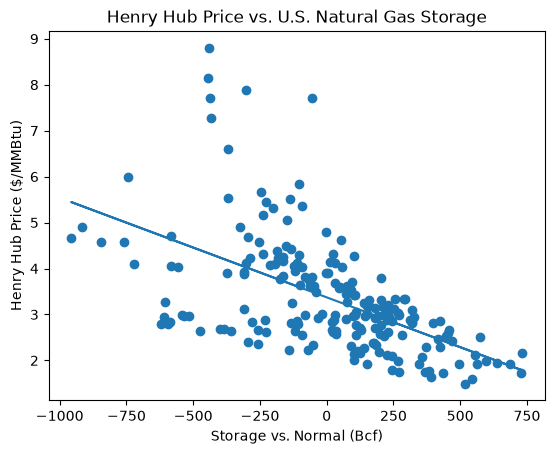

In [60]:
# Chart 1 - Storage vs. Henry Hub price

x = storage_price["storage_vs_normal_bcf"]
y = storage_price["price"]

plt.scatter(x, y)

# calculate the best-fit straight line
slope, intercept = np.polyfit(x, y, 1)

# plot that line
plt.plot(x, slope * x + intercept)

plt.xlabel("Storage vs. Normal (Bcf)")
plt.ylabel("Henry Hub Price ($/MMBtu)")
plt.title("Henry Hub Price vs. U.S. Natural Gas Storage")

plt.show()

# plt.scatter() tells matplotlib that we want a scatter plot, where every observation becomes one dot in a (x coordinate, y coordinate) format
# np.polyfit(x, y, 1) asks NumPy to find the best-fitting first-degree polynomial through those points (y = mx+b)
# plt.plot(x, slope * x + intercept) calculates the predicted y value from that equation for every x and draws a line through them

In [61]:
slope, intercept

(np.float64(-0.0021678238343101892), np.float64(3.3720259916373))

In [62]:
# the trendline has a slope of about -0.00217 $/MMBtu per Bcf and an intercept of about $3.37/MMBtu
# this is an association, not necessarily a causal relationship
# we're not saying that adding 100 Bcf to storage causes prices to fall $0.22 - many other factors like weather, production, LNG demand, etc. are all changing too
# we're saying the historical data shows that 100 Bcf higher storage relative to normal is associated with roughly $0.22/MMBtu lower prices

In [63]:
# Chart 2: LNG exports vs. Henry Hub price

# Create a pandas DataFrame containing LNG exports and Henry Hub price

lng_price = con.sql("""
    SELECT
        month,
        lng_exports_bcfd,
        price

    FROM market_data

    ORDER BY month
""").df()

lng_price.head()

,month,lng_exports_bcfd,price
0,2010-01-01,0.062548,5.832105
1,2010-02-01,0.181714,5.320000
2,2010-03-01,0.062419,4.290870
3,2010-04-01,0.128400,4.033810
4,2010-05-01,0.062258,4.140000


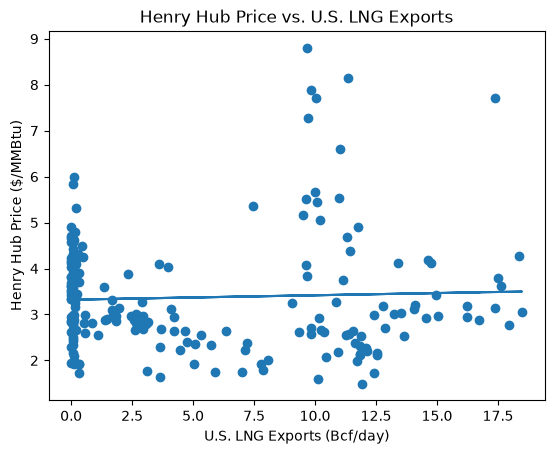

In [64]:
# Chart 2 - LNG exports vs. Henry Hub price

x = lng_price["lng_exports_bcfd"]
y = lng_price["price"]

plt.scatter(x, y)

# calculate the best-fit straight line
slope, intercept = np.polyfit(x, y, 1)

# plot the best-fit line
plt.plot(x, slope * x + intercept)

plt.xlabel("U.S. LNG Exports (Bcf/day)")
plt.ylabel("Henry Hub Price ($/MMBtu)")
plt.title("Henry Hub Price vs. U.S. LNG Exports")

plt.show()

In [65]:
slope, intercept

(np.float64(0.009572505849060534), np.float64(3.3218662490902635))

In [66]:
# we can see clustering to the left representing the pre-2016 period, and just a weak correlation overall which proves the 0.04 we calculated earlier
# shows the absolute level of LNG exports by itself does a very poor job explaining the absolute level of Henry Hub prices across 2010–2026

In [67]:
# pull our main market variables from SQL into pandas

market_plot = con.sql("""
    SELECT
        month,
        price,
        production_bcfd,
        lng_exports_bcfd,
        storage_vs_normal_bcf

    FROM market_data

    ORDER BY month
""").df()

market_plot.head()

,month,price,production_bcfd,lng_exports_bcfd,storage_vs_normal_bcf
0,2010-01-01,5.832105,56.039774,0.062548,-101.882353
1,2010-02-01,5.320000,57.238929,0.181714,-200.411765
2,2010-03-01,4.290870,57.280194,0.062419,-102.294118
3,2010-04-01,4.033810,57.563933,0.128400,56.000000
4,2010-05-01,4.140000,57.954710,0.062258,12.529412


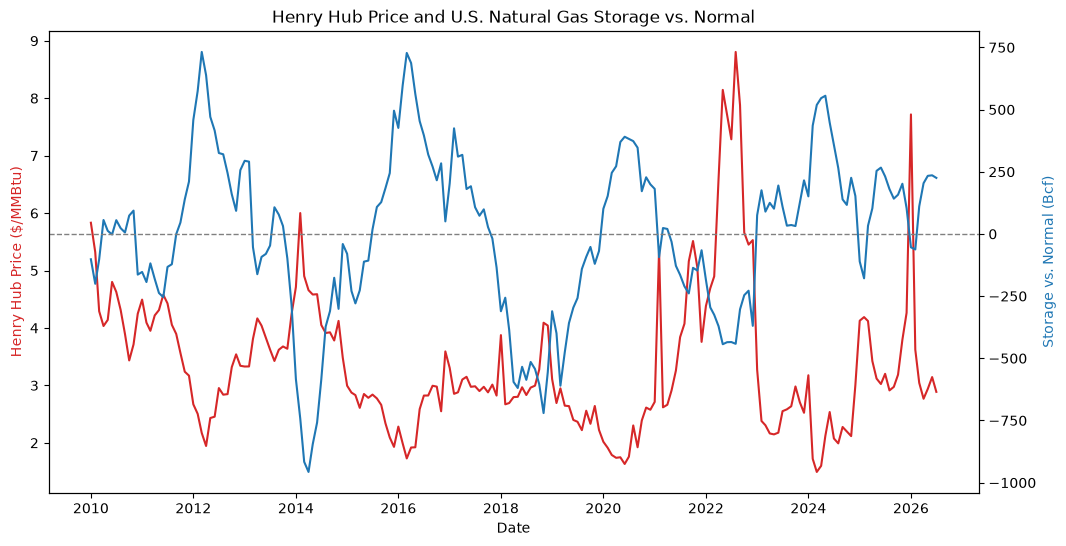

In [68]:
# let's compare Henry Hub price and storage balance over time

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    market_plot["month"],
    market_plot["price"],
    color="tab:red",
    label="Henry Hub Price"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Henry Hub Price ($/MMBtu)", color="tab:red")

ax2 = ax1.twinx()

ax2.plot(
    market_plot["month"],
    market_plot["storage_vs_normal_bcf"],
    color="tab:blue",
    label="Storage vs. Normal"
)

ax2.set_ylabel("Storage vs. Normal (Bcf)", color="tab:blue")

# zero represents exactly normal storage
ax2.axhline(0, color="gray", linestyle="--", linewidth=1)

plt.title("Henry Hub Price and U.S. Natural Gas Storage vs. Normal")
plt.show()

# fig, ax1 = plt.subplots(...) creates the overall figure (fig) and our first set of axes (ax1)
# ax2 = ax1.twinx() creates a second y-axis that shares the same x-axis

In [69]:
# during the price spike in 2022, the storage relative to normal was less than normal, but when the storage enters a surplus again in 2023-2024, the prices drops
# earlier dips in storage did not create price spikes like the magnitude of the one in 2022
# so storage alone cannot explain the 2022 price spike, so let's dig into it

In [70]:
# pull out just the 2020–2024 period so we can inspect around the 2022 episode

# examine the fundamentals surrounding the 2022 price spike (2 years on either end)

episode_2022 = con.sql("""
    SELECT
        month,
        price,
        production_bcfd,
        lng_exports_bcfd,
        storage_vs_normal_bcf

    FROM market_data

    WHERE YEAR(month) BETWEEN 2020 AND 2024

    ORDER BY month
""").df()

episode_2022.head()

,month,price,production_bcfd,lng_exports_bcfd,storage_vs_normal_bcf
0,2020-01-01,2.018571,97.369452,8.074355,101.117647
1,2020-02-01,1.913158,95.498310,7.785724,152.588235
2,2020-03-01,1.788636,95.251677,7.879645,245.705882
3,2020-04-01,1.739048,95.024733,7.015533,272.000000
4,2020-05-01,1.748500,87.865419,5.885097,369.529412


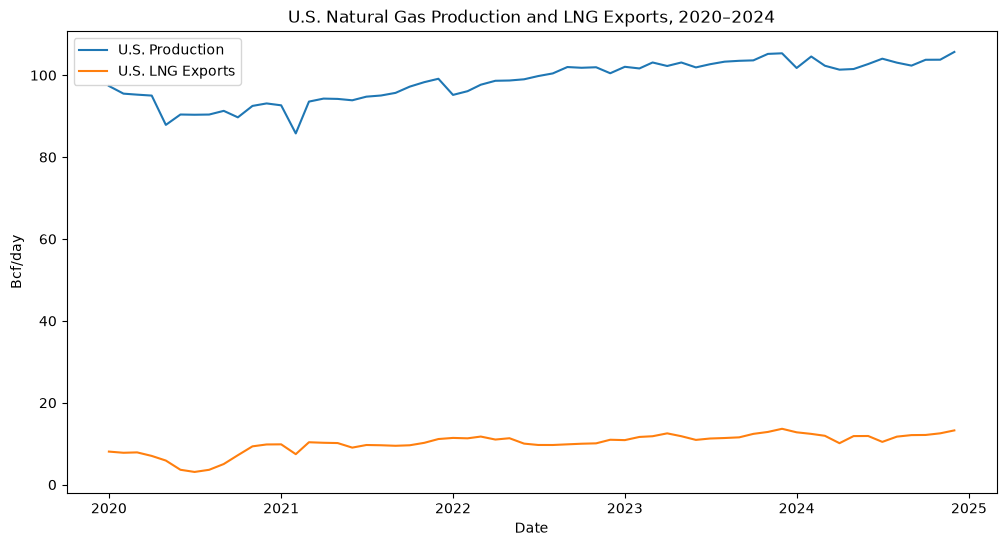

In [71]:
# make a chart of production and LNG exports during that period (2020-2024)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    episode_2022["month"],
    episode_2022["production_bcfd"],
    label="U.S. Production"
)

ax.plot(
    episode_2022["month"],
    episode_2022["lng_exports_bcfd"],
    label="U.S. LNG Exports"
)

ax.set_xlabel("Date")
ax.set_ylabel("Bcf/day")
ax.set_title("U.S. Natural Gas Production and LNG Exports, 2020–2024")
ax.legend()

plt.show()

In [72]:
# looks like production fell slightly around the beginning of 2022 but exports stayed relatively constant, which would tend to push prices higher
# also, storage was below normal, further tending to push prices higher
# on top of this, the Ukraine-Russia war started around this time which would have helped push prices higher even more

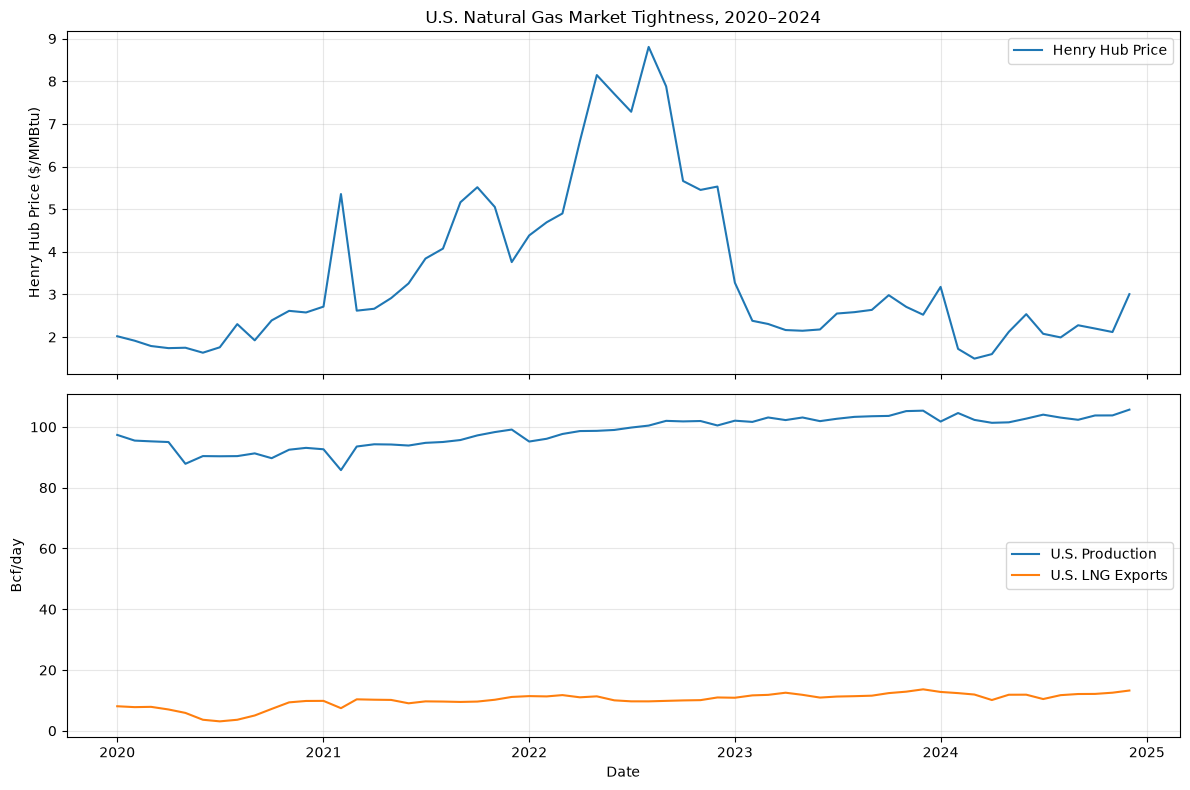

In [73]:
# we want to see whether the 2022 Henry Hub spike lines up with the market tightening
# instead of cramming production, exports, storage, and price onto one axis, we'll use two stacked charts sharing the same date axis - that will be much easier to interpret

# Focus on the modern LNG market
modern_market = market_plot[
    (market_plot["month"] >= "2020-01-01") &
    (market_plot["month"] < "2025-01-01")
].copy()

# Create two vertically stacked charts that share the same date axis
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True
)

# TOP CHART: Henry Hub price
ax1.plot(
    modern_market["month"],
    modern_market["price"],
    label="Henry Hub Price"
)

ax1.set_ylabel("Henry Hub Price ($/MMBtu)")
ax1.set_title("U.S. Natural Gas Market Tightness, 2020–2024")
ax1.legend()
ax1.grid(alpha=0.3)


# BOTTOM CHART: Production and LNG exports
ax2.plot(
    modern_market["month"],
    modern_market["production_bcfd"],
    label="U.S. Production"
)

ax2.plot(
    modern_market["month"],
    modern_market["lng_exports_bcfd"],
    label="U.S. LNG Exports"
)

ax2.set_ylabel("Bcf/day")
ax2.set_xlabel("Date")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# plt.subplots(2, 1, ...) means 2 rows × 1 column, so we're creating two charts stacked vertically - Python gives us ax1 for the top chart and ax2 for the bottom chart
# sharex=True tells matplotlib that both charts represent the same time period, so they should share one date axis - that's especially useful here because you can visually draw an imaginary vertical line through, say, early 2022 and compare everything happening at that moment
# modern_market = market_plot[...].copy() is creating a new DataFrame containing only 2020–2024 - we aren't deleting anything from market_plot; we're just making a subset for this particular analysis

In [74]:
# after the production dip in 2022, production slowly climbs back to where it was originally - exports are relatively constant, but the price keeps climbing
# that observation reinforces that the production dip alone cannot explain the 2022 price spike
# now let's include storage to see how that might've affected prices

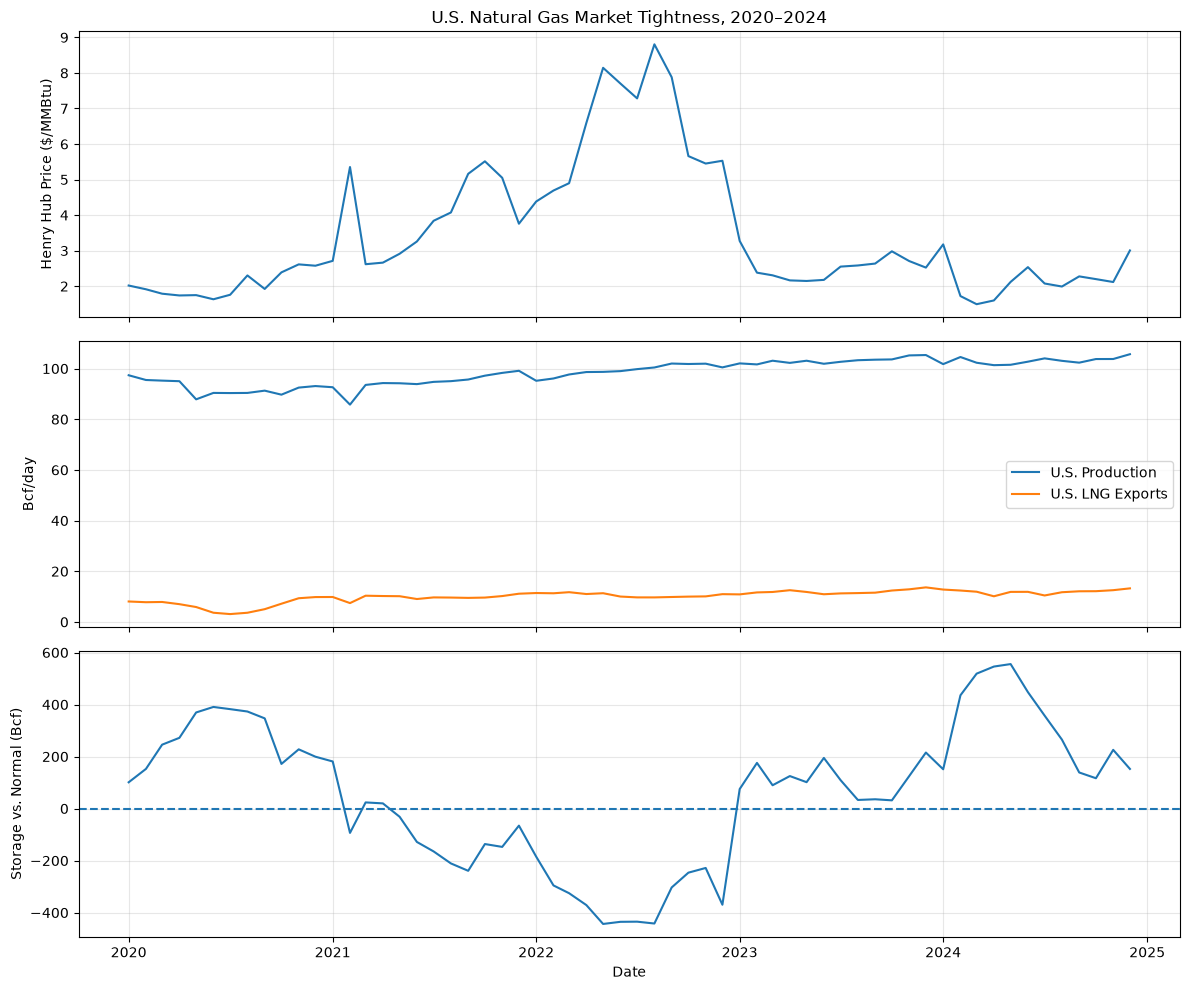

In [75]:
# Create three vertically stacked charts sharing the same date axis
fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1,
    figsize=(12, 10),
    sharex=True
)

# TOP: Henry Hub price
ax1.plot(
    modern_market["month"],
    modern_market["price"]
)

ax1.set_ylabel("Henry Hub Price ($/MMBtu)")
ax1.set_title("U.S. Natural Gas Market Tightness, 2020–2024")
ax1.grid(alpha=0.3)


# MIDDLE: Production and LNG exports
ax2.plot(
    modern_market["month"],
    modern_market["production_bcfd"],
    label="U.S. Production"
)

ax2.plot(
    modern_market["month"],
    modern_market["lng_exports_bcfd"],
    label="U.S. LNG Exports"
)

ax2.set_ylabel("Bcf/day")
ax2.legend()
ax2.grid(alpha=0.3)


# BOTTOM: Storage relative to normal
ax3.plot(
    modern_market["month"],
    modern_market["storage_vs_normal_bcf"]
)

ax3.axhline(0, linestyle="--")

ax3.set_ylabel("Storage vs. Normal (Bcf)")
ax3.set_xlabel("Date")
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ax3.axhline(0, linestyle="--") draws a horizontal line at 0 Bcf
# above 0 → storage surplus
# below 0 → storage deficit

In [76]:
# these graphs further reinforce the strong relationship between storage and price and weak relationship between individual supply/demand components and price
# storage acts as a buffer between supply and demand

In [77]:
# Let's analyze changes in price vs changes in storage surplus/deficit from month to month

# Calculate how the storage surplus/deficit changes from one month to the next
modern_market["change_storage_vs_normal_bcf"] = (
    modern_market["storage_vs_normal_bcf"].diff()
)

# Calculate the month-to-month change in Henry Hub price
modern_market["price_change"] = (
    modern_market["price"].diff()
)

modern_market[
    [
        "month",
        "storage_vs_normal_bcf",
        "change_storage_vs_normal_bcf",
        "price",
        "price_change"
    ]
].head(10)

,month,storage_vs_normal_bcf,change_storage_vs_normal_bcf,price,price_change
120,2020-01-01,101.117647,NaN,2.018571,NaN
121,2020-02-01,152.588235,51.470588,1.913158,-0.105414
122,2020-03-01,245.705882,93.117647,1.788636,-0.124522
123,2020-04-01,272.000000,26.294118,1.739048,-0.049589
124,2020-05-01,369.529412,97.529412,1.748500,0.009452
125,2020-06-01,390.705882,21.176471,1.631818,-0.116682
126,2020-07-01,382.294118,-8.411765,1.758636,0.126818
127,2020-08-01,373.187500,-9.106618,2.302381,0.543745
128,2020-09-01,346.812500,-26.375000,1.922381,-0.380000
129,2020-10-01,171.687500,-175.125000,2.389091,0.466710


In [78]:
# Correlation between monthly change in storage balance and monthly change in Henry Hub price

change_correlation = modern_market[
    ["change_storage_vs_normal_bcf", "price_change"]
].corr()

change_correlation

# instead of SQL's CORR(x, y), we're using pandas DataFrame.corr()
# because we supplied two columns, pandas will give us a 2x2 correlation matrix
# the diagonal will always be 1 because every variable is perfectly correlated with itself

,change_storage_vs_normal_bcf,price_change
change_storage_vs_normal_bcf,1.000000,-0.671488
price_change,-0.671488,1.000000


In [79]:
# from 2020–2024, monthly changes in storage relative to normal exhibited a strong negative correlation (~−0.67) with monthly changes in Henry Hub prices
# we're seeing that, not only the absolute values, but the rate of change of storage and price are also strongly correlated
# the market isn't just responding to how tight/loose inventories are at any moment, but also to whether conditions are getting tighter or looser

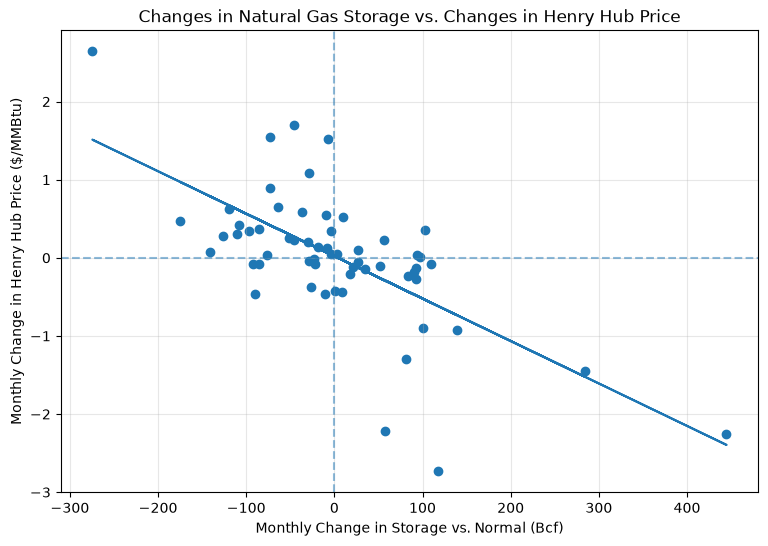

In [80]:
# plot the monthly change in storage balance vs. monthly change in Henry Hub price

x = modern_market["change_storage_vs_normal_bcf"]
y = modern_market["price_change"]

plt.figure(figsize=(9, 6))

plt.scatter(x, y)

# Add best-fit line
valid = x.notna() & y.notna()

slope, intercept = np.polyfit(
    x[valid],
    y[valid],
    1
)

plt.plot(
    x[valid],
    slope * x[valid] + intercept
)

# Reference lines
plt.axhline(0, linestyle="--", alpha=0.5)
plt.axvline(0, linestyle="--", alpha=0.5)

plt.xlabel("Monthly Change in Storage vs. Normal (Bcf)")
plt.ylabel("Monthly Change in Henry Hub Price ($/MMBtu)")
plt.title("Changes in Natural Gas Storage vs. Changes in Henry Hub Price")

plt.grid(alpha=0.3)

plt.show()

In [81]:
# Henry Hub prices are more closely associated with overall market tightness than with individual supply or demand variables in isolation
# storage relative to normal provides a much stronger signal of the balance between supply and demand
# during 2020–2024, monthly changes in storage relative to normal had a −0.67 correlation with monthly Henry Hub price changes

In [82]:
# let's find the months with the largest changes in Henry Hub price

modern_market[
    [
        "month",
        "change_storage_vs_normal_bcf",
        "price_change",
        "price",
        "storage_vs_normal_bcf"
    ]
].sort_values(
    "price_change",
    key=abs,
    ascending=False
).head(10)

# normally sort_values() would sort from the largest positive price change downward, but key=abs tells pandas to sort based on the absolute magnitude instead
# i.e. +$2.50 and −$2.50 are treated as equally large moves
# this should tell us which months generated the biggest price shocks on the scatterplot

,month,change_storage_vs_normal_bcf,price_change,price,storage_vs_normal_bcf
134,2021-03-01,117.117647,-2.735423,2.618261,23.705882
133,2021-02-01,-274.529412,2.641053,5.353684,-93.411765
156,2023-01-01,444.680147,-2.256524,3.273000,75.117647
153,2022-10-01,56.875000,-2.219976,5.660500,-246.312500
147,2022-04-01,-45.705882,1.697739,6.596000,-371.000000
148,2022-05-01,-72.470588,1.548762,8.144762,-443.470588
151,2022-08-01,-7.106618,1.521152,8.805652,-441.812500
169,2024-02-01,284.470588,-1.454690,1.721500,435.588235
143,2021-12-01,81.687500,-1.292773,3.757727,-65.562500
140,2021-09-01,-28.375000,1.087338,5.161429,-239.187500


In [83]:
# Month	    Δ Storage vs. Normal	Δ Henry Hub     Interpretation
# Feb 2021	−274.5 Bcf	            +$2.64	        lower storage vs normal → price increase
# Mar 2021	+117.1 Bcf	            −$2.74	        higher storage vs normal → price drop
# Jan 2023	+444.7 Bcf	            −$2.26	        higher storage vs normal → price drop
# Apr 2022	−45.7 Bcf	            +$1.70	        lower storage vs normal → price increase
# May 2022	−72.5 Bcf	            +$1.55	        lower storage vs normal → price increase
# Feb 2024	+284.5 Bcf	            −$1.45	        higher storage vs normal → price drop

# this result was to be expected

In [84]:
# create a final summary table containing the key findings and correlations

summary_stats = modern_market[
    [
        "price",
        "production_bcfd",
        "lng_exports_bcfd",
        "storage_vs_normal_bcf"
    ]
].corr()

summary_stats

# .corr() will now give a 4x4 correlation matrix since we're defining 4 variables
# modern_market is the 2020+ subset, where LNG exports are a meaningful part of the U.S. gas balance - that's the market structure we're most interested in explaining

,price,production_bcfd,lng_exports_bcfd,storage_vs_normal_bcf
price,1.000000,0.019548,0.092140,-0.882319
production_bcfd,0.019548,1.000000,0.802038,0.002938
lng_exports_bcfd,0.092140,0.802038,1.000000,-0.165168
storage_vs_normal_bcf,-0.882319,0.002938,-0.165168,1.000000


In [85]:
# price and storage vs normal are strongly correlated since storage vs normal gives the best gauge for how tight or loose the market is
# in the mass balance equation accumulation = in - out, the accuation term is the most important here
# production and exports are strongly correlated because if there is an increasing global demand for LNG exports, then production will have to keep up with that demand

In [86]:
# create a final 2020–2024 Henry Hub price + storage-vs-normal chart

final_chart = modern_market[
    [
        "month",
        "price",
        "storage_vs_normal_bcf"
    ]
].copy()

final_chart.head()

# .copy() tells pandas to create a separate copy of these selected columns (i.e. final_chart) rather than accidentally modifying part of modern_market

,month,price,storage_vs_normal_bcf
120,2020-01-01,2.018571,101.117647
121,2020-02-01,1.913158,152.588235
122,2020-03-01,1.788636,245.705882
123,2020-04-01,1.739048,272.000000
124,2020-05-01,1.748500,369.529412


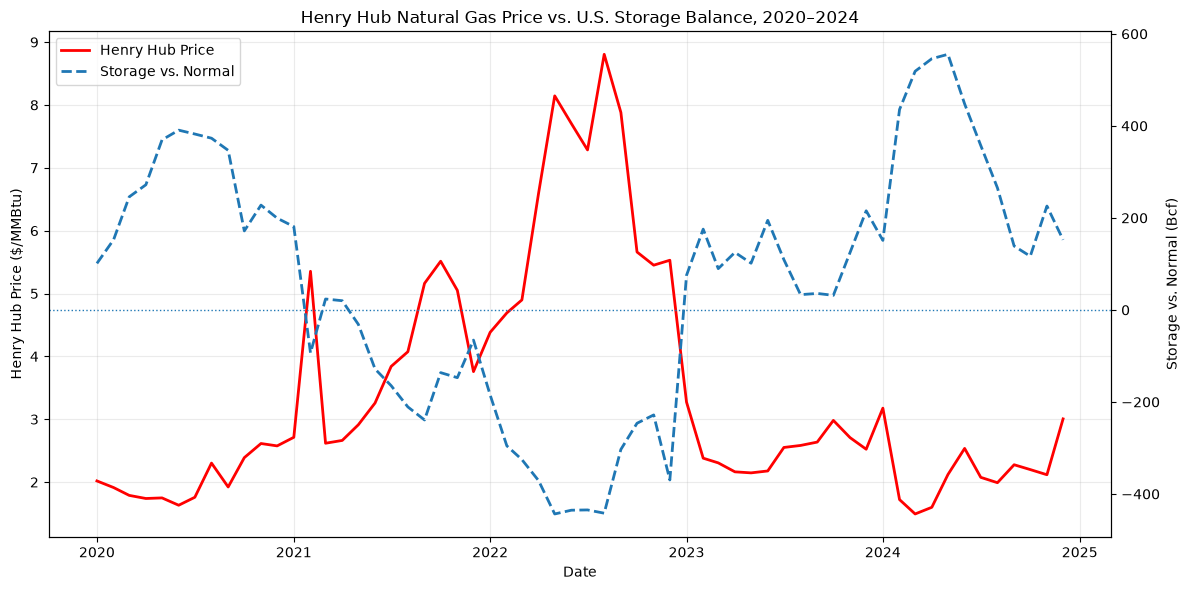

In [87]:
# Create portfolio-quality chart of Henry Hub price and storage balance

fig, ax1 = plt.subplots(figsize=(12, 6))

# Henry Hub price
ax1.plot(
    final_chart["month"],
    final_chart["price"],
    linewidth=2,
    color="red",
    label="Henry Hub Price"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Henry Hub Price ($/MMBtu)")
ax1.set_title(
    "Henry Hub Natural Gas Price vs. U.S. Storage Balance, 2020–2024"
)

# Create second y-axis for storage
ax2 = ax1.twinx()

ax2.plot(
    final_chart["month"],
    final_chart["storage_vs_normal_bcf"],
    linewidth=2,
    linestyle="--",
    label="Storage vs. Normal"
)

ax2.axhline(0, linewidth=1, linestyle=":")
ax2.set_ylabel("Storage vs. Normal (Bcf)")

# Combine both legends - since there's 2 y-axes, ax1 and ax2 technically maintain separate legends, so we're retrieving the line and label from each axis, combining them with +, and putting them into one legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

ax1.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "../charts/henry_hub_price_vs_storage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# linestyle="--" makes the storage series dashed, so the two lines are distinguishable
# dpi=300 gives us a high-resolution image suitable for a portfolio/README
# bbox_inches="tight" trims unnecessary whitespace around the saved figure
# ../charts/... means go up from notebooks into the main project folder, then enter and save in the charts folder

# Final Conclusions

This analysis examined how U.S. dry natural gas production, LNG exports, and storage conditions relate to Henry Hub natural gas prices.

## Key Findings

### 1. Current storage levels relative to normal storage levels was the strongest indicator of Henry Hub prices

For the 2020–2024 period, Henry Hub price and storage relative to normal had a correlation of approximately **-0.88**.

When storage shifted below normal, prices generally increased. When storage shifted above normal, prices generally declined.

The relationship was also visible in monthly changes, not just absolute values. The correlation between the monthly change in storage levels relative to normal storage levels and the monthly change in Henry Hub price was approximately **-0.67**.

### 2. Production alone did not explain natural gas prices

The correlation of dry U.S. natural gas production with Henry Hub prices was very weak.

This suggests that individual supply/demand variables do not appropriately explain why prices move the way they do.

### 3. LNG exports became an increasingly important source of U.S. natural gas demand

U.S. LNG exports increased substantially over the period analyzed and became a much larger share of U.S. natural gas production post-2016.

However, LNG exports alone showed little direct correlation with Henry Hub prices during 2020–2024, reinforcing that individual supply/demand variables do not appropriately explain why prices move the way they do.

Production and LNG exports were strongly positively correlated, suggesting that rising U.S. production has helped accommodate the growth in LNG export demand.

## Overall Conclusion

Henry Hub prices appear to be driven less by any single supply or demand variable and more by the **balance between supply and demand aka storage levels relative to normal storage levels**.

Among the variables analyzed, storage levels relative to normal storage levels provided the clearest measure of how tight or loose the market is. Production and LNG exports help determine the underlying supply-demand balance, while storage provides a useful indicator of whether the market is oversupplied or undersupplied.